# Visualizações e respostas - Bolsa Família, Auxílio Brasil e Novo Bolsa Família (2019 a 2026)

Nesse notebook estão os gráficos finais e as respostas das 5 perguntas, feitos a partir da base tratada pela limpeza
(`src/limpeza.py`). Quase tudo vem da gold (`data/gold/municipio_mes.parquet` e `data/gold/brasil_mes.parquet`), que
tem as famílias, os valores, a população e a taxa por município e mês, e só a distribuição do valor da parcela lê a
silver (`data/silver/pagamentos`), que tem um registro por pagamento. Antes de rodar, é preciso rodar na raiz do
projeto o `python src/eda.py` e o `python src/limpeza.py`, e cada gráfico é salvo em `reports/figuras` para usar no
relatório. Os valores estão em reais nominais, sem correção pela inflação.

A primeira célula carrega as bibliotecas, define a cor de cada fase (as mesmas do notebook 02) e lê as tabelas da
gold. Também monta a tabela anual por município (`anual`), com a média de famílias de cada mês do ano dividida pela
população do ano, que é a taxa usada nos gráficos de UF, de região e no mapa.

In [1]:
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
gold = raiz / "data" / "gold"
silver = raiz / "data" / "silver" / "pagamentos"
eda = raiz / "data" / "_eda"
malhas = raiz / "data" / "bronze" / "referencias" / "malhas_ibge_2025"
figuras = raiz / "reports" / "figuras"
figuras.mkdir(parents=True, exist_ok=True)

# uma cor por fase do programa (as mesmas do notebook 02)
fases = ["Bolsa Família", "Auxílio Brasil", "Novo Bolsa Família"]
cor = {"Bolsa Família": "#2a78d6", "Auxílio Brasil": "#eb6834", "Novo Bolsa Família": "#1baf7a"}
tinta = "#0b0b0b"
tinta2 = "#52514e"
grade = "#e1e0d9"
eixo = "#c3c2b7"
fundo = "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": fundo, "axes.facecolor": fundo, "axes.edgecolor": eixo, "axes.labelcolor": tinta2,
    "xtick.color": tinta2, "ytick.color": tinta2, "text.color": tinta, "axes.grid": True,
    "grid.color": grade, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2, "text.parse_math": False,
})
transicoes = {"2020-03": "pandemia", "2021-11": "Auxílio Brasil", "2023-03": "Novo Bolsa Família"}

con = duckdb.connect()
con.execute("SET enable_progress_bar = false")


def br(x, casas=0):
    # número no padrão brasileiro: 1.234,5
    texto = format(x, ",." + str(casas) + "f")
    return texto.replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")


def milhar(valor, posicao):
    return br(valor)


def mes_ano(data):
    return data.strftime("%m/%Y")


def marcar_transicoes(ax, rotulos=True):
    for mes in transicoes:
        x = pd.Timestamp(mes + "-01")
        ax.axvline(x, color=eixo, lw=1, ls="--", zorder=0)
        if rotulos:
            ax.annotate(transicoes[mes], (x, 1), xycoords=("data", "axes fraction"), xytext=(3, -2),
                        textcoords="offset points", va="top", fontsize=8, color=tinta2)


def salvar(fig, nome):
    fig.savefig(figuras / nome, dpi=200, bbox_inches="tight")


# os valores vêm como decimal da gold; aqui viram float para os gráficos
mun = con.execute(f"""
    SELECT * REPLACE (valor_total::DOUBLE AS valor_total, valor_mes_corrente::DOUBLE AS valor_mes_corrente,
                      valor_retroativo::DOUBLE AS valor_retroativo, valor_por_familia::DOUBLE AS valor_por_familia)
    FROM read_parquet('{(gold / "municipio_mes.parquet").as_posix()}')""").fetchdf()
pais = con.execute(f"""
    SELECT * REPLACE (valor_total::DOUBLE AS valor_total, valor_mes_corrente::DOUBLE AS valor_mes_corrente,
                      valor_retroativo::DOUBLE AS valor_retroativo, valor_por_familia::DOUBLE AS valor_por_familia)
    FROM read_parquet('{(gold / "brasil_mes.parquet").as_posix()}')""").fetchdf()
mun["mes"] = pd.to_datetime(mun["mes"])
pais["mes"] = pd.to_datetime(pais["mes"])

# taxa anual por município: média das famílias de cada mês do ano dividida pela população do ano
anual = mun.groupby(["cod_municipio", "municipio", "uf", "regiao", "ano"], as_index=False).agg(
    familias=("familias", "mean"), populacao=("populacao", "first"), valor_mes=("valor_mes_corrente", "sum"),
    familias_corr=("familias_mes_corrente", "sum"))
anual["taxa"] = 1e5 * anual["familias"] / anual["populacao"]
anual["valor_por_familia"] = anual["valor_mes"] / anual["familias_corr"]

print("Meses:", pais["mes"].min().strftime("%m/%Y"), "a", pais["mes"].max().strftime("%m/%Y"), "|",
      len(mun), "linhas município × mês |", anual["cod_municipio"].nunique(), "municípios")
print("Município × mês sem população:", mun["populacao"].isna().sum())

Meses: 01/2019 a 09/2026 | 518022 linhas município × mês | 5571 municípios
Município × mês sem população: 0


## 1. Famílias atendidas por mês

Esse gráfico mostra a série das famílias atendidas no Brasil, com uma cor para cada fase do programa e as
transições marcadas. A família é o NIS distinto no mês, então nov/2021 já aparece sem a repetição entre as
duas bases.

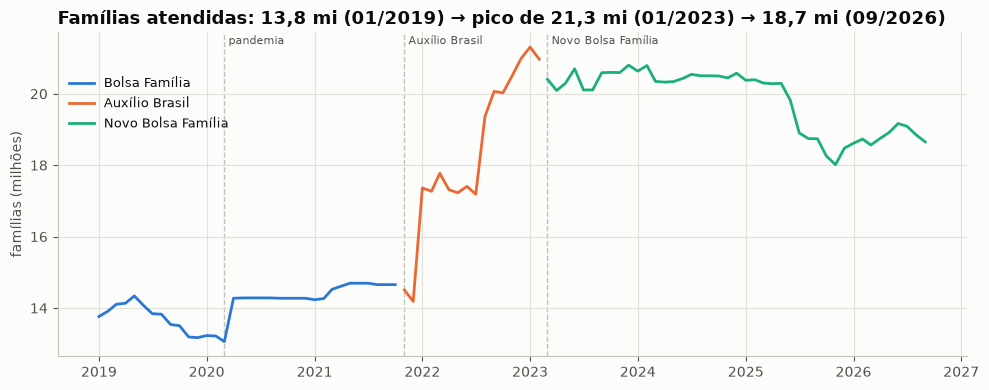

In [2]:
inicio = pais.iloc[0]
fim = pais.iloc[-1]
pico = pais.loc[pais["familias"].idxmax()]

fig, ax = plt.subplots(figsize=(10, 4))
for fase in fases:
    s = pais[pais["fase"] == fase]
    ax.plot(s["mes"], s["familias"] / 1e6, color=cor[fase], label=fase)
marcar_transicoes(ax)
ax.set_ylabel("famílias (milhões)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(milhar))
ax.set_title("Famílias atendidas: " + br(inicio["familias"] / 1e6, 1) + " mi (" + mes_ano(inicio["mes"])
             + ") → pico de " + br(pico["familias"] / 1e6, 1) + " mi (" + mes_ano(pico["mes"]) + ") → "
             + br(fim["familias"] / 1e6, 1) + " mi (" + mes_ano(fim["mes"]) + ")")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9), fontsize=9)
plt.tight_layout()
salvar(fig, "fig01_familias_por_mes.png")
plt.show()

## 2. Antes e depois da limpeza

Aqui comparo as famílias de cada mês somando os arquivos como vieram do Portal (resumos da EDA, em `data/_eda/mensal`)
com as famílias da base tratada. A diferença aparece em nov/2021, que estava publicado nas duas bases, e a tabela
embaixo do gráfico é o log de limpeza com todas as decisões.

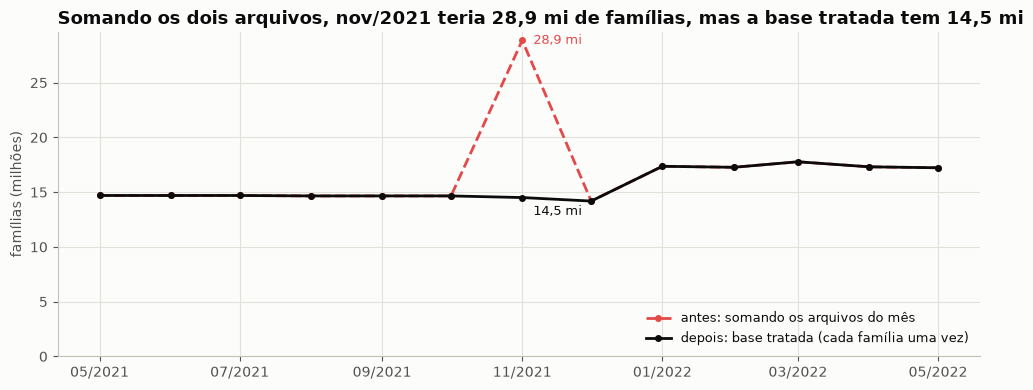

,problema,decisão,justificativa,linhas afetadas
0,Colunas com nomes do CSV (maiúsculas e acentos...,Renomear para snake_case e converter os tipos:...,"Permite calcular direto sobre a base, e na amo...",1.633.465.096
1,Arquivo de nov/2021 do Bolsa Família com os ró...,Trocar as duas colunas nesse arquivo: a compet...,"É assim nos outros 93 arquivos, e o dicionário...",14.508.113 (em 1.812 os meses mudam)
2,Nov/2021 publicado nas duas bases (o arquivo d...,"Manter o arquivo do Auxílio Brasil e, do Bolsa...","É o mesmo pagamento publicado duas vezes, entã...",14.355.279 removidas
3,Duplicados exatos (a mesma linha inteira mais ...,"Remover, mantendo uma","Mesma parcela registrada duas vezes, e nenhum ...",3.975 removidas
4,NIS ausente,"Manter a linha com NIS nulo, fora da contagem ...","Não dá para atribuir a família, mas o valor fo...",15.601
5,"CPF ausente (o CPF vem mascarado, ***.123.456-**)",Tirar a coluna de CPF da silver e manter a mar...,O CPF mascarado não é chave nem variável de an...,190.307.921
6,Mesmo NIS e mesmo mês de referência mais de um...,Manter e marcar chave_repetida,"Pode ser complemento legítimo, e as famílias s...",1.208.763
7,Pagamento retroativo (referência anterior ao m...,"Manter, marcar retroativo e guardar meses_atraso","É pagamento real, e a gold separa o valor do m...",8.202.217
8,Valores extremos da parcela,Manter e marcar valor_extremo quando o valor é...,"Regra explícita, porque são raros, plausíveis ...",17.495
9,"Município identificado pelo código SIAFI, não ...","Trocar pelo código IBGE e trazer nome, UF e re...",O código IBGE liga a base à população e à malh...,0 sem correspondência


In [3]:
antes = con.execute(f"""
    SELECT strptime(periodo, '%Y%m') AS mes, sum(familias) AS familias
    FROM read_parquet('{(eda / "mensal" / "*.parquet").as_posix()}') GROUP BY periodo ORDER BY periodo""").fetchdf()
antes["mes"] = pd.to_datetime(antes["mes"])
janela_antes = antes[(antes["mes"] >= "2021-05-01") & (antes["mes"] <= "2022-05-01")]
janela_depois = pais[(pais["mes"] >= "2021-05-01") & (pais["mes"] <= "2022-05-01")]
nov_antes = antes.loc[antes["mes"] == "2021-11-01", "familias"].iloc[0]
nov_depois = pais.loc[pais["mes"] == "2021-11-01", "familias"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(janela_antes["mes"], janela_antes["familias"] / 1e6, color="#e34948", ls="--", marker="o", ms=4,
        label="antes: somando os arquivos do mês")
ax.plot(janela_depois["mes"], janela_depois["familias"] / 1e6, color=tinta, marker="o", ms=4,
        label="depois: base tratada (cada família uma vez)")
ax.annotate(br(nov_antes / 1e6, 1) + " mi", (pd.Timestamp("2021-11-01"), nov_antes / 1e6), xytext=(8, 0),
            textcoords="offset points", va="center", color="#e34948", fontsize=9)
ax.annotate(br(nov_depois / 1e6, 1) + " mi", (pd.Timestamp("2021-11-01"), nov_depois / 1e6), xytext=(8, -10),
            textcoords="offset points", va="center", color=tinta, fontsize=9)
ax.set_ylabel("famílias (milhões)")
ax.set_ylim(bottom=0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_title("Somando os dois arquivos, nov/2021 teria " + br(nov_antes / 1e6, 1) + " mi de famílias, mas a base "
             "tratada tem " + br(nov_depois / 1e6, 1) + " mi")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
salvar(fig, "fig02_antes_depois_nov2021.png")
plt.show()

log = pd.read_csv(raiz / "reports" / "log_limpeza.csv", sep=";")
log

## 3. Cobertura por UF em 2025

As barras ordenadas mostram as famílias atendidas por 100 mil habitantes em cada UF, usando a média mensal de
2025 e a população estimada pelo IBGE. A linha tracejada é a taxa do Brasil.

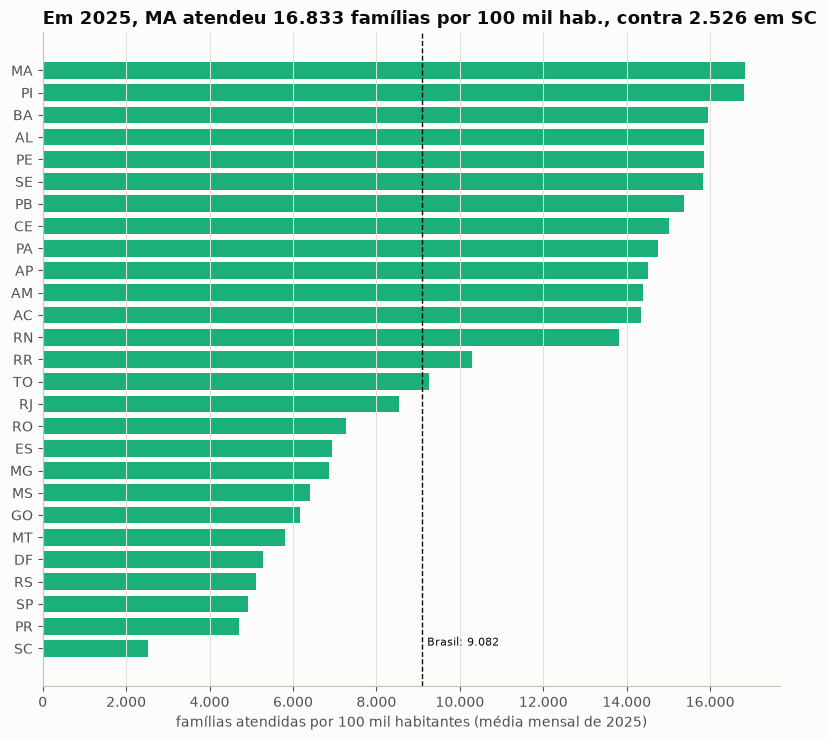

In [4]:
uf = anual[anual["ano"] == 2025].groupby(["uf", "regiao"], as_index=False)[["familias", "populacao"]].sum()
uf["taxa"] = 1e5 * uf["familias"] / uf["populacao"]
uf = uf.sort_values("taxa")
brasil_2025 = 1e5 * uf["familias"].sum() / uf["populacao"].sum()

fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(uf["uf"], uf["taxa"], color=cor["Novo Bolsa Família"], height=0.75)
ax.axvline(brasil_2025, color=tinta, lw=1, ls="--")
ax.annotate("Brasil: " + br(brasil_2025), (brasil_2025, 0), xytext=(4, 2), textcoords="offset points",
            fontsize=8, color=tinta)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(milhar))
ax.set_xlabel("famílias atendidas por 100 mil habitantes (média mensal de 2025)")
maior = uf.iloc[-1]
menor = uf.iloc[0]
ax.set_title("Em 2025, " + maior["uf"] + " atendeu " + br(maior["taxa"]) + " famílias por 100 mil hab., contra "
             + br(menor["taxa"]) + " em " + menor["uf"])
plt.tight_layout()
salvar(fig, "fig03_taxa_por_uf_2025.png")
plt.show()

## 4. Taxa dos municípios em cada região

O boxplot compara a distribuição da taxa dos municípios entre as regiões em 2025, com a mediana em preto.
Assim dá para ver o nível de cada região e também a diferença entre os municípios dela.

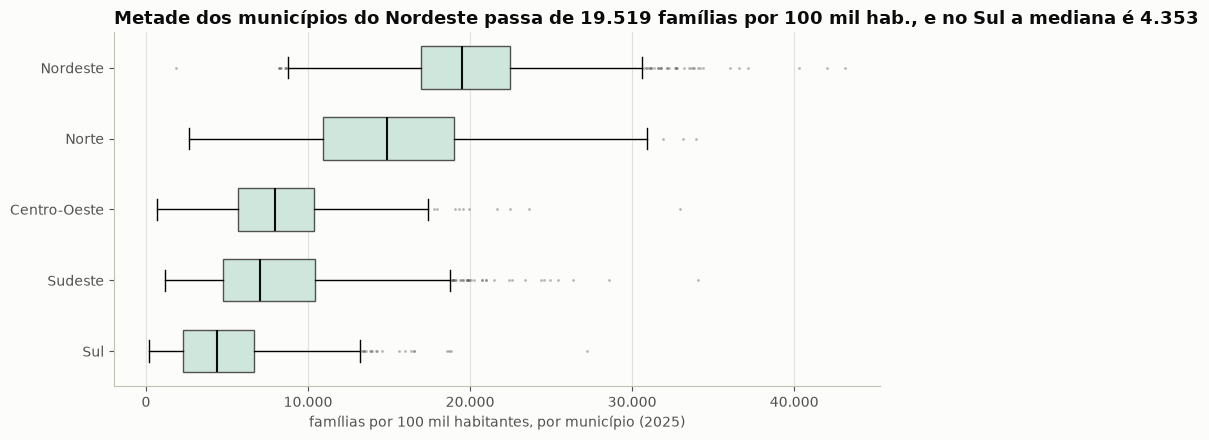

,count,mean,std,min,25%,50%,75%,max
regiao,,,,,,,,
Centro-Oeste,468.0,8397.0,3751.0,703.0,5654.0,7956.0,10379.0,32948.0
Nordeste,1794.0,19846.0,4589.0,1828.0,16991.0,19519.0,22476.0,43146.0
Norte,450.0,15039.0,5568.0,2684.0,10938.0,14880.0,18995.0,33942.0
Sudeste,1668.0,8023.0,4311.0,1184.0,4775.0,7038.0,10418.0,34057.0
Sul,1191.0,4846.0,3209.0,178.0,2297.0,4353.0,6674.0,27199.0


In [5]:
m25 = anual[anual["ano"] == 2025].copy()
ordem = m25.groupby("regiao")["taxa"].median().sort_values(ascending=False).index.tolist()
grupos = []
for regiao in ordem:
    grupos.append(m25.loc[m25["regiao"] == regiao, "taxa"].values)

fig, ax = plt.subplots(figsize=(9, 4.5))
caixas = ax.boxplot(grupos, tick_labels=ordem, orientation="horizontal", patch_artist=True, widths=0.6,
                    flierprops={"marker": "o", "markersize": 2, "markerfacecolor": tinta2, "markeredgewidth": 0,
                                "alpha": 0.4},
                    medianprops={"color": tinta, "linewidth": 1.5})
for caixa in caixas["boxes"]:
    caixa.set_facecolor("#cfe6dc")
    caixa.set_edgecolor(tinta2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(milhar))
ax.set_xlabel("famílias por 100 mil habitantes, por município (2025)")
mediana = m25.groupby("regiao")["taxa"].median()
ax.set_title("Metade dos municípios do " + ordem[0] + " passa de " + br(mediana[ordem[0]])
             + " famílias por 100 mil hab., e no " + ordem[-1] + " a mediana é " + br(mediana[ordem[-1]]))
plt.tight_layout()
salvar(fig, "fig04_taxa_municipios_por_regiao.png")
plt.show()
m25.groupby("regiao")["taxa"].describe().round(0)

## 5. Valor da parcela em cada fase

Essa célula lê a silver e conta os pagamentos em faixas de R$ 10, só com as parcelas do próprio mês (sem os
retroativos). A mediana de cada fase sai das faixas (`mediana_da_faixa`), por isso é arredondada para a dezena.

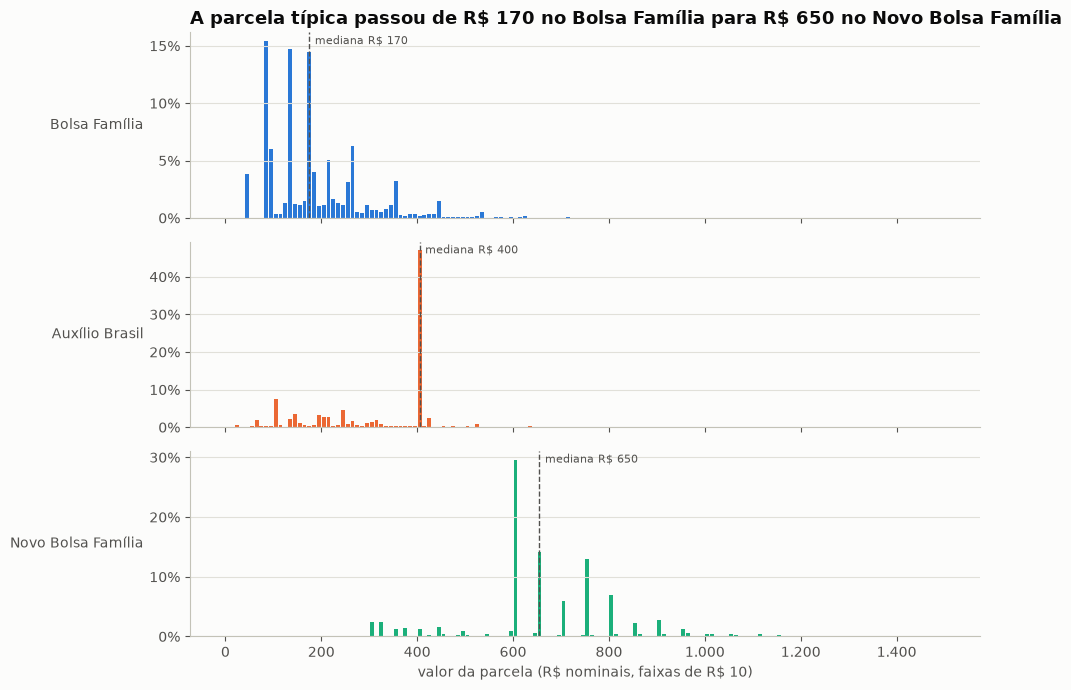

In [6]:
faixas = con.execute(f"""
    SELECT fase, floor(valor / 10) * 10 AS faixa, count(*) AS pagamentos
    FROM read_parquet('{(silver / "*" / "*" / "*.parquet").as_posix()}')
    WHERE NOT retroativo GROUP BY ALL""").fetchdf()
faixas["faixa"] = faixas["faixa"].astype(float)


def mediana_da_faixa(tabela):
    tabela = tabela.sort_values("faixa")
    acumulado = tabela["pagamentos"].cumsum() / tabela["pagamentos"].sum()
    return tabela.loc[acumulado >= 0.5, "faixa"].iloc[0]


fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
medianas = {}
for ax, fase in zip(axs, fases):
    f = faixas[(faixas["fase"] == fase) & (faixas["faixa"] < 1500)]
    total = faixas.loc[faixas["fase"] == fase, "pagamentos"].sum()
    medianas[fase] = mediana_da_faixa(faixas[faixas["fase"] == fase])
    ax.bar(f["faixa"] + 5, 100 * f["pagamentos"] / total, width=8, color=cor[fase])
    ax.axvline(medianas[fase] + 5, color=tinta2, lw=1, ls="--")
    ax.annotate("mediana R$ " + br(medianas[fase]), (medianas[fase] + 5, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -2), textcoords="offset points", va="top", fontsize=8, color=tinta2)
    ax.set_ylabel(fase, rotation=0, ha="right", va="center")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
axs[-1].set_xlabel("valor da parcela (R$ nominais, faixas de R$ 10)")
axs[-1].xaxis.set_major_formatter(mtick.FuncFormatter(milhar))
axs[0].set_title("A parcela típica passou de R$ " + br(medianas["Bolsa Família"]) + " no Bolsa Família para R$ "
                 + br(medianas["Novo Bolsa Família"]) + " no Novo Bolsa Família")
plt.tight_layout()
salvar(fig, "fig05_valor_da_parcela.png")
plt.show()

## 6. Porte do município e cobertura

Cada ponto é um município, com a população no eixo x em escala log e a taxa no eixo y, e a linha preta é a
mediana por faixa de população. Separei por região porque no país inteiro os municípios muito pequenos se
concentram no Sul e no Sudeste, onde a cobertura é baixa, e isso esconde a relação dentro de cada região.

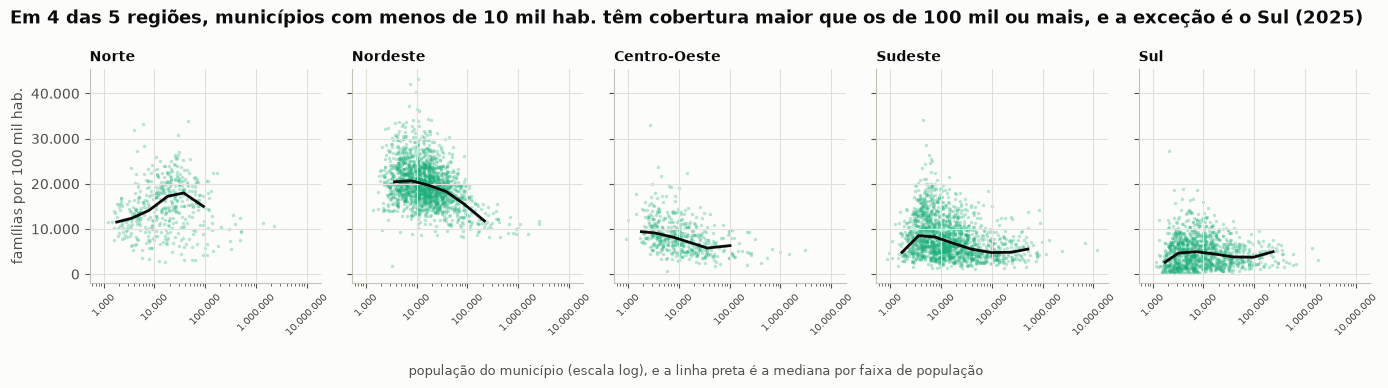

Taxa mediana por região, municípios com menos de 10 mil hab. e com 100 mil ou mais,
e correlação de Spearman entre população e taxa:
  Norte 12.905 10.983 0,16
  Nordeste 20.791 12.060 −0,33
  Centro-Oeste 8.743 4.927 −0,43
  Sudeste 8.389 4.816 −0,29
  Sul 4.364 4.321 0,02


In [7]:
regioes = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
cortes = np.logspace(np.log10(m25["populacao"].min()), np.log10(m25["populacao"].max()), 12)
fig, axs = plt.subplots(1, 5, figsize=(14, 3.8), sharey=True, sharex=True)
pequenos_maior = 0
excecoes = []
for ax, regiao in zip(axs, regioes):
    r = m25[m25["regiao"] == regiao].copy()
    ax.scatter(r["populacao"], r["taxa"], s=6, alpha=0.3, color=cor["Novo Bolsa Família"], linewidths=0)
    r["faixa"] = pd.cut(r["populacao"], cortes, include_lowest=True)
    med = r.groupby("faixa", observed=True).agg(x=("populacao", "median"), y=("taxa", "median"),
                                                n=("taxa", "size"))
    med = med[med["n"] >= 10]  # faixa com poucos municípios deixa a mediana instável
    ax.plot(med["x"], med["y"], color=tinta, lw=2)
    ax.set_xscale("log")
    ax.set_title(regiao, fontsize=10)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(milhar))
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    pequenos = r.loc[r["populacao"] < 10_000, "taxa"].median()
    grandes = r.loc[r["populacao"] >= 100_000, "taxa"].median()
    # só conta como maior se a diferença for de pelo menos 10%
    if pequenos >= 1.1 * grandes:
        pequenos_maior += 1
    else:
        excecoes.append(regiao)
axs[0].set_ylabel("famílias por 100 mil hab.")
axs[0].yaxis.set_major_formatter(mtick.FuncFormatter(milhar))
fig.supxlabel("população do município (escala log), e a linha preta é a mediana por faixa de população",
              fontsize=9, color=tinta2)
titulo = "Em " + str(pequenos_maior) + " das 5 regiões, municípios com menos de 10 mil hab. têm cobertura maior que os de "
titulo += "100 mil ou mais (2025)"
if len(excecoes) > 0:
    titulo = titulo[:-7] + ", e a exceção é o " + " e o ".join(excecoes) + " (2025)"
fig.suptitle(titulo, x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
salvar(fig, "fig06_porte_e_cobertura_por_regiao.png")
plt.show()
print("Taxa mediana por região, municípios com menos de 10 mil hab. e com 100 mil ou mais,")
print("e correlação de Spearman entre população e taxa:")
for regiao in regioes:
    r = m25[m25["regiao"] == regiao]
    pequenos = r.loc[r["populacao"] < 10_000, "taxa"].median()
    grandes = r.loc[r["populacao"] >= 100_000, "taxa"].median()
    print(" ", regiao, br(pequenos), br(grandes), br(r["populacao"].rank().corr(r["taxa"].rank()), 2))

## 7. Mapa da cobertura por município (2025)

O mapa usa a malha municipal do IBGE de 2025 e pinta cada município pela taxa de famílias por 100 mil
habitantes, em classes de 5 mil. As duas lagoas do Rio Grande do Sul aparecem na malha mas não são municípios, por
isso ficam sem taxa.

Polígonos sem taxa: 2 (as duas lagoas do RS não são municípios)


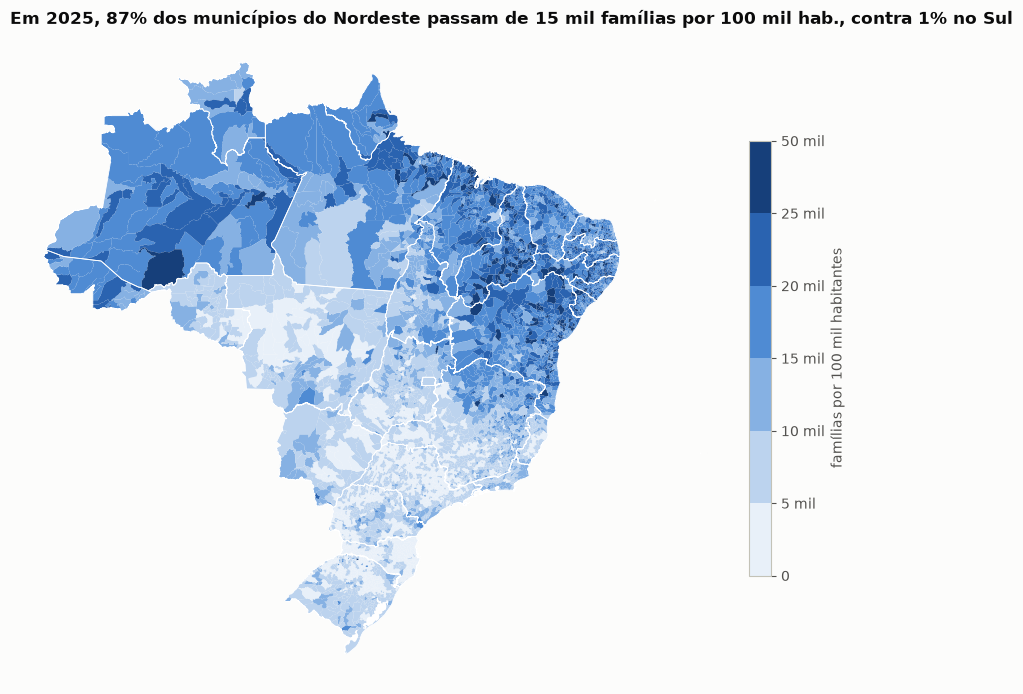

regiao
Centro-Oeste     4.7
Nordeste        87.3
Norte           49.3
Sudeste          7.7
Sul              0.8
Name: alto, dtype: float64

In [8]:
municipios = gpd.read_file("zip://" + (malhas / "BR_Municipios_2025.zip").as_posix())
ufs = gpd.read_file("zip://" + (malhas / "BR_UF_2025.zip").as_posix())
municipios["cod_municipio"] = municipios["CD_MUN"].astype(int)
mapa = municipios.merge(m25[["cod_municipio", "taxa"]], on="cod_municipio", how="left")
print("Polígonos sem taxa:", mapa["taxa"].isna().sum(), "(as duas lagoas do RS não são municípios)")

# classes fixas, de 5 em 5 mil, numa só cor do claro para o escuro
limites = [0, 5_000, 10_000, 15_000, 20_000, 25_000, 50_000]
cores = ["#e8f0f9", "#bcd3ee", "#86b1e3", "#4f8bd3", "#2a63b0", "#163f7a"]
escala = ListedColormap(cores)
norma = BoundaryNorm(limites, escala.N)

fig, ax = plt.subplots(figsize=(9, 9))
mapa.plot(ax=ax, column="taxa", cmap=escala, norm=norma, linewidth=0, missing_kwds={"color": "#ffffff"})
ufs.boundary.plot(ax=ax, color="#ffffff", linewidth=0.6)
ax.set_axis_off()
barra = fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=escala), ax=ax, shrink=0.5, pad=0.01,
                     ticks=limites[:-1] + [limites[-1]])
barra.ax.set_yticklabels(["0", "5 mil", "10 mil", "15 mil", "20 mil", "25 mil", "50 mil"])
barra.set_label("famílias por 100 mil habitantes")
acima = m25.assign(alto=m25["taxa"] >= 15_000).groupby("regiao")["alto"].mean() * 100
ax.set_title("Em 2025, " + br(acima["Nordeste"]) + "% dos municípios do Nordeste passam de 15 mil famílias por 100 mil "
             "hab., contra " + br(acima["Sul"]) + "% no Sul", fontsize=12)
plt.tight_layout()
salvar(fig, "fig07_mapa_taxa_municipios_2025.png")
plt.show()
acima.round(1)

## 8. Valor médio por família

Esse gráfico mostra o valor médio por família em cada mês (parcela do próprio mês dividida pelas famílias com
parcela no mês), e a linha pontilhada é o piso legal do Auxílio Brasil. Os valores são nominais.

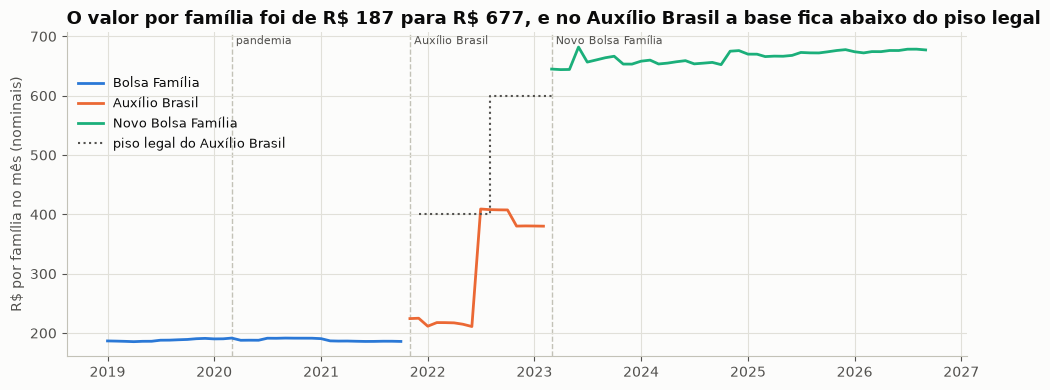

,valor_mes_corrente,familias_mes_corrente,valor_por_familia
fase,,,
Auxílio Brasil,9.200100e+10,293427768,313.54
Bolsa Família,9.020367e+10,479086199,188.28
Novo Bolsa Família,5.667759e+11,852135591,665.12


In [9]:
# piso garantido por família no Auxílio Brasil: R$ 400 (dez/2021 a jul/2022) e R$ 600 (ago/2022 a fev/2023)
piso = pd.DataFrame({"mes": pd.to_datetime(["2021-12-01", "2022-08-01", "2023-03-01"]), "piso": [400, 600, 600]})

fig, ax = plt.subplots(figsize=(10, 4))
for fase in fases:
    s = pais[pais["fase"] == fase]
    ax.plot(s["mes"], s["valor_por_familia"], color=cor[fase], label=fase)
ax.step(piso["mes"], piso["piso"], where="post", color=tinta2, lw=1.5, ls=":", label="piso legal do Auxílio Brasil")
marcar_transicoes(ax)
ax.set_ylabel("R$ por família no mês (nominais)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(milhar))
ax.set_title("O valor por família foi de R$ " + br(pais["valor_por_familia"].iloc[0]) + " para R$ "
             + br(pais["valor_por_familia"].iloc[-1]) + ", e no Auxílio Brasil a base fica abaixo do piso legal")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9), fontsize=9)
plt.tight_layout()
salvar(fig, "fig08_valor_por_familia.png")
plt.show()
resumo = pais.groupby("fase")[["valor_mes_corrente", "familias_mes_corrente"]].sum()
resumo["valor_por_familia"] = resumo["valor_mes_corrente"] / resumo["familias_mes_corrente"]
resumo.round(2)

## 9. Regiões em 2019, 2022 e 2025

As barras comparam a taxa de cada região em 2019 (Bolsa Família), 2022 (último ano inteiro do Auxílio Brasil)
e 2025 (Novo Bolsa Família). A população de 2022 é interpolada entre as estimativas de 2021 e 2024, como está
no log de limpeza.

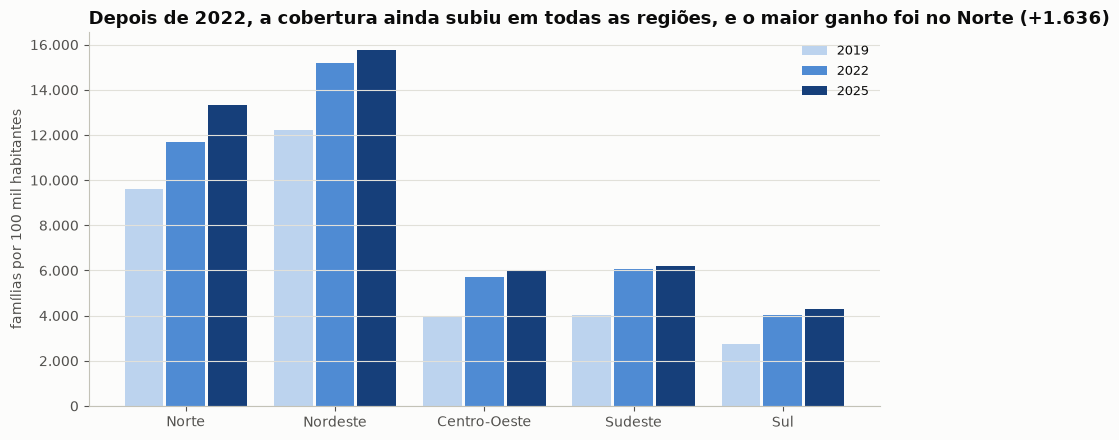

ano,2019,2022,2025
regiao,,,
Norte,9600.0,11671.0,13307.0
Nordeste,12238.0,15196.0,15758.0
Centro-Oeste,3933.0,5714.0,5978.0
Sudeste,4031.0,6063.0,6180.0
Sul,2757.0,4018.0,4279.0


In [10]:
reg = anual[anual["ano"].isin([2019, 2022, 2025])].groupby(["regiao", "ano"])[["familias", "populacao"]].sum()
reg["taxa"] = 1e5 * reg["familias"] / reg["populacao"]
tabela = reg["taxa"].unstack("ano").loc[regioes]

fig, ax = plt.subplots(figsize=(9, 4.5))
largura = 0.26
tons = {2019: "#bcd3ee", 2022: "#4f8bd3", 2025: "#163f7a"}
x = np.arange(len(regioes))
for i, ano in enumerate([2019, 2022, 2025]):
    ax.bar(x + (i - 1) * (largura + 0.02), tabela[ano], width=largura, color=tons[ano], label=str(ano))
ax.set_xticks(x, regioes)
ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(milhar))
ax.set_ylabel("famílias por 100 mil habitantes")
ganho = tabela[2025] - tabela[2022]
subiram = int((ganho > 0).sum())
quem = "todas as regiões" if subiram == 5 else str(subiram) + " das 5 regiões"
ax.set_title("Depois de 2022, a cobertura ainda subiu em " + quem + ", e o maior ganho foi no " + ganho.idxmax()
             + " (+" + br(ganho.max()) + ")")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
salvar(fig, "fig09_regioes_2019_2022_2025.png")
plt.show()
tabela.round(0)

## 10. Respostas às 5 perguntas

Essa célula calcula os números usados nas respostas, que estão logo abaixo dela.

In [11]:
def taxa_brasil(ano):
    a = anual[anual["ano"] == ano]
    return 1e5 * a["familias"].sum() / a["populacao"].sum()


print("1) Famílias por 100 mil habitantes no Brasil (média mensal do ano):")
for ano in sorted(anual["ano"].unique()):
    print("  ", ano, br(taxa_brasil(ano)))

print("2) Valor médio por família no mês, por fase (R$ nominais):")
por_fase = pais.groupby("fase")[["valor_mes_corrente", "familias_mes_corrente"]].sum()
for fase in fases:
    print("  ", fase, br(por_fase.loc[fase, "valor_mes_corrente"] / por_fase.loc[fase, "familias_mes_corrente"], 2))

print("3) Coeficiente de variação da taxa entre as UFs:")
uf_ano = anual.groupby(["uf", "ano"])[["familias", "populacao"]].sum()
uf_ano["taxa"] = 1e5 * uf_ano["familias"] / uf_ano["populacao"]
for ano in [2019, 2022, 2025]:
    t = uf_ano.xs(ano, level="ano")["taxa"]
    print("  ", ano, br(t.std() / t.mean(), 3))

print("4) Regiões em que municípios com menos de 10 mil hab. têm taxa pelo menos 10% maior que os de 100 mil ou",
      "mais:", pequenos_maior, "de 5 (exceção:", ", ".join(excecoes) + ")")

w = anual.pivot_table(index=["cod_municipio", "regiao"], columns="ano", values="taxa").reset_index()
w["cresc_19_22"] = w[2022] - w[2019]
w["var_22_25"] = w[2025] - w[2022]
topo = w[w["cresc_19_22"] >= w["cresc_19_22"].quantile(0.75)]
print("5) Dos 25% de municípios que mais cresceram de 2019 a 2022,", br(100 * (topo["var_22_25"] >= 0).mean(), 1),
      "% mantiveram ou ampliaram a taxa até 2025 (todos:", br(100 * (w["var_22_25"] >= 0).mean(), 1), "%)")
w.groupby("regiao")[["cresc_19_22", "var_22_25"]].median().round(0)

1) Famílias por 100 mil habitantes no Brasil (média mensal do ano):
   2019 6.559
   2020 6.612
   2021 6.812
   2022 8.701
   2023 9.654
   2024 9.641
   2025 9.082
   2026 8.783
2) Valor médio por família no mês, por fase (R$ nominais):
   Bolsa Família 188,28
   Auxílio Brasil 313,54
   Novo Bolsa Família 665,12
3) Coeficiente de variação da taxa entre as UFs:
   2019 0,515
   2022 0,455
   2025 0,447
4) Regiões em que municípios com menos de 10 mil hab. têm taxa pelo menos 10% maior que os de 100 mil ou mais: 4 de 5 (exceção: Sul)
5) Dos 25% de municípios que mais cresceram de 2019 a 2022, 51,8 % mantiveram ou ampliaram a taxa até 2025 (todos: 54,4 %)


ano,cresc_19_22,var_22_25
regiao,,
Centro-Oeste,1759.0,50.0
Nordeste,2799.0,414.0
Norte,1910.0,1032.0
Sudeste,1758.0,-1.0
Sul,987.0,12.0


## Conclusões

1\. Como evoluiu o número de famílias atendidas por 100 mil habitantes entre 2019 e 2026, e o que mudou em cada
transição?

A taxa passou de 6.559 famílias por 100 mil habitantes em 2019 para cerca de 9.650 em 2023 e 2024 e caiu para 8.783
em 2026 (até setembro). O salto veio com o Auxílio Brasil, que trouxe 3,27 milhões de famílias em janeiro de 2022 e
2,32 milhões em agosto de 2022, e a passagem para o Novo Bolsa Família começou com a saída de 1,33 milhão e a entrada
de 0,77 milhão de famílias em março de 2023, e desde 2024 a cobertura cai devagar.

2\. Quanto mudou o valor médio pago por família em cada fase do programa?

Em valores nominais, o valor médio por família no mês foi de R$ 188 no Bolsa Família, R$ 314 no Auxílio Brasil e
R$ 665 no Novo Bolsa Família, e a parcela mais comum passou de R$ 170 para R$ 650. O valor do Auxílio Brasil está
subestimado nessa base, porque fica abaixo do piso legal da época (gráfico 8), então a comparação entre as fases
precisa dessa ressalva.

3\. Quais UFs e regiões têm a maior cobertura por habitante, e a diferença entre elas aumentou ou diminuiu ao longo
do período?

O Nordeste tem a maior cobertura, seguido do Norte, e o Sul tem a menor. Em 2025 o Maranhão atendeu 16.833 famílias
por 100 mil habitantes, 6,7 vezes a taxa de Santa Catarina (2.526), e a diferença entre as UFs diminuiu até 2024 (o
coeficiente de variação caiu de 0,52 para 0,43) e voltou a crescer um pouco em 2025 e 2026 (0,45).

4\. Municípios pequenos têm cobertura proporcionalmente maior que os grandes?

Sim em quatro das cinco regiões. No Nordeste, no Centro-Oeste e no Sudeste a taxa mediana dos municípios com menos de
10 mil habitantes é de 72% a 77% maior que a dos municípios com 100 mil ou mais, no Norte é 17% maior e no Sul fica
praticamente igual, e no país inteiro a relação parece fraca porque os municípios muito pequenos se concentram no Sul
e no Sudeste.

5\. Onde a cobertura mais cresceu entre 2019 e 2022, e esse crescimento se manteve depois da criação do Novo Bolsa
Família?

A cobertura mais cresceu no Nordeste, que ganhou 2.958 famílias por 100 mil habitantes de 2019 a 2022, seguido do
Norte (2.071), e o crescimento se manteve, porque de 2022 para 2025 a taxa ainda subiu em todas as regiões, mais no
Norte (1.636) e no Nordeste (562). Dos 25% de municípios que mais cresceram até 2022, 52% mantiveram ou aumentaram a
taxa até 2025, quase o mesmo que no total (54%).